First 5 records:
   Study_Hours  Attendance_Percent  Previous_Marks  Sleep_Hours  \
0          3.6                  73              81          4.7   
1          7.7                  60              83          6.6   
2          6.1                  98              64          5.2   
3          5.2                  57              80          6.9   
4          2.1                  85              86          8.3   

   Assignment_Score  Final_Marks Performance  
0                94           92        High  
1                76          100        High  
2                67           98        High  
3                49           96        High  
4                78           86        High  

Training records: 160
Testing records: 40

First 10 actual categories:
['High', 'High', 'High', 'High', 'Medium', 'Medium', 'Medium', 'Medium', 'High', 'High']

First 10 predicted categories:
['Medium' 'High' 'High' 'High' 'Medium' 'Medium' 'High' 'Medium' 'High'
 'High']

SVM Accuracy: 87.5 %

C

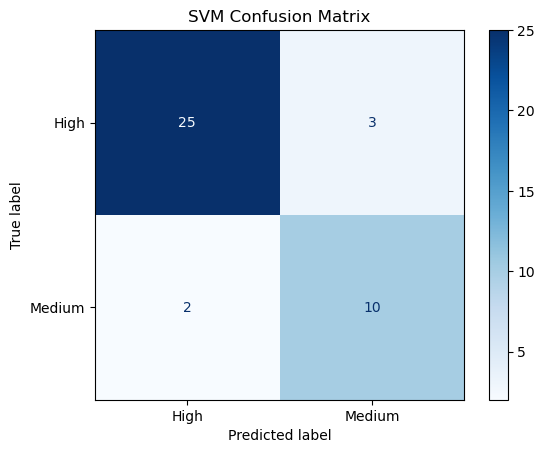

In [1]:

# Assignment 9: SVM Classification

# Step 1: Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Step 2: Load dataset
df = pd.read_csv("Student_Performance_Dataset.csv")

print("First 5 records:")
print(df.head())

# Step 3: Select features and target
features = [
    "Study_Hours",
    "Attendance_Percent",
    "Previous_Marks",
    "Sleep_Hours",
    "Assignment_Score"
]

X = df[features]
y = df["Performance"]

# Step 4: Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))

# Step 5: Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Create and train SVM model
model = SVC(kernel="rbf")
model.fit(X_train_scaled, y_train)

# Step 7: Predict performance
y_pred = model.predict(X_test_scaled)

print("\nFirst 10 actual categories:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predicted categories:")
print(y_pred[:10])

# Step 8: Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("\nSVM Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

# Step 9: Confusion matrix
labels = sorted(y.unique())

print("Class order:", labels)
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=labels))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=labels,
    cmap="Blues"
)

plt.title("SVM Confusion Matrix")
plt.show()


## Result
The Support Vector Machine (SVM) classification algorithm was successfully implemented on the Student Performance Dataset. The model predicted student performance categories and was evaluated using accuracy, a classification report, and a confusion matrix.

## Conclusion
SVM was used to classify student performance based on selected student-related features. StandardScaler was applied to standardize the features because SVM is sensitive to differences in feature scales.